# 02 · Tier 1: VADER baseline (stock vs + Taglish lexicon)

**How VADER works.** It has a dictionary of ~7,500 English words, each with a score from -4 to +4
(*good* = +1.9, *bad* = -2.5). It adds up the scores of the words in a sentence and applies a few rules:
a negator before a word flips it (*not good*), boosters make it stronger (*very good*), ALL CAPS and
"!!!" add emphasis, and after *but* the second half counts more. The total is squashed into a
**compound** score between -1 and +1. Standard cut-offs: ≥ 0.05 positive, ≤ -0.05 negative, else neutral.

**The problem here:** stock VADER knows no Tagalog. *"ang galing ni smugg"* has no word it knows → score 0 → neutral.

**What we add** (`notebooks/src/taglish_lexicon.py`): ~120 Tagalog / FlipTop words with scores (*galing, lupet, solid,
yabang, luto, corny, b\*\*o* …), Tagalog negators (*hindi, wala, huwag*) and boosters (*sobrang, napaka, grabe*).
The Taglish version reads `text_vader`, where spellings are already normalised and *pero / kaso* became *but*.

> Install: `pip install vaderSentiment` (preferred - it also reads emoji) or `pip install nltk` and
> `nltk.download("vader_lexicon")`. The code uses whichever is installed.

In [2]:
import sys, pathlib
NB_DIR = pathlib.Path.cwd().resolve()
if NB_DIR.name != "notebooks":        # Jupyter was started in the repo root instead of notebooks/
    NB_DIR = NB_DIR / "notebooks"
ROOT = NB_DIR.parent                  # repo root (data/, results/, prompts.md ...)
sys.path.insert(0, str(NB_DIR))       # so "from src import ..." finds notebooks/src/

import pandas as pd
import matplotlib.pyplot as plt

from src import config, data, evaluate as ev
from src.profanity import mask, mask_frame     # curse words are masked in everything shown
from src.cleaning import basic_clean, for_vader
from src.taglish_lexicon import make_vader, vader_label, TAGLISH_LEXICON

train, test = data.load_split()
hard = data.load_hard_cases()
print(len(train), "train |", len(test), "test |", len(hard), "hard cases")

700 train | 300 test | 30 hard cases


## 1. Stock VADER

In [3]:
stock = make_vader(taglish=False)       # build and use the stock one FIRST (see note in taglish_lexicon.py)

demo = [
    "The battle was good.",
    "The battle was GOOD!!!",
    "The battle was not good.",
    "Ang galing ni Smugglaz!",
    "Hindi magaling si Loonie dito.",
    "Sobrang lupet ni Abra!",
]
mask_frame(pd.DataFrame([{"text": s, **stock.polarity_scores(basic_clean(s))} for s in demo]).round(3))

,text,neg,neu,pos,compound
0,The battle was good.,0.347,0.267,0.387,0.077
1,The battle was GOOD!!!,0.285,0.220,0.495,0.442
2,The battle was not good.,0.625,0.375,0.000,-0.613
3,Ang galing ni Smugglaz!,0.000,1.000,0.000,0.000
4,Hindi magaling si Loonie dito.,0.000,1.000,0.000,0.000
5,Sobrang lupet ni Abra!,0.000,1.000,0.000,0.000


163/300 test comments get compound = 0 (no known word) -> predicted neutral
== VADER (stock) ==
              precision    recall  f1-score   support

    negative      0.558     0.183     0.276       131
     neutral      0.287     0.653     0.398        72
    positive      0.430     0.412     0.421        97

    accuracy                          0.370       300
   macro avg      0.425     0.416     0.365       300
weighted avg      0.452     0.370     0.352       300



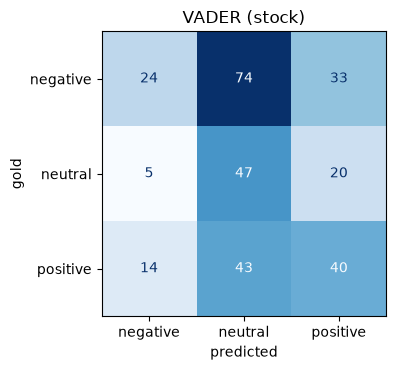

{'model': 'VADER (stock)',
 'tier': '1 rule-based',
 'accuracy': 0.37,
 'macro_f1': 0.3650732617634091,
 'hard_acc': 0.3,
 'sec_per_1k': 0.09166466673680893,
 'cost_per_1k_usd': 0.0}

In [4]:
def stock_predict(texts):
    return [vader_label(stock.polarity_scores(basic_clean(t))["compound"]) for t in texts]

pred_stock, sec_stock = ev.timed_predict(stock_predict, test["text"])
hard_stock = stock_predict(hard["text"])

zero = sum(stock.polarity_scores(t)["compound"] == 0 for t in test["text_clean"])
print(f"{zero}/{len(test)} test comments get compound = 0 (no known word) -> predicted neutral")
ev.report(test["label"], pred_stock, "VADER (stock)")
ev.plot_confusion(test["label"], pred_stock, "VADER (stock)")
plt.show()
ev.save_run("VADER (stock)", "1 rule-based", test, pred_stock, hard, hard_stock, sec_stock)

## 2. VADER + Taglish lexicon

In [5]:
tl = make_vader(taglish=True)
print(len(TAGLISH_LEXICON), "Taglish words added")
mask_frame(pd.DataFrame([{"text": s, "text_vader": for_vader(s), **tl.polarity_scores(for_vader(s))} for s in demo]).round(3))

118 Taglish words added


,text,text_vader,neg,neu,pos,compound
0,The battle was good.,The battle was good.,0.347,0.267,0.387,0.077
1,The battle was GOOD!!!,The battle was GOOD!!!,0.285,0.220,0.495,0.442
2,The battle was not good.,The battle was not good.,0.625,0.375,0.000,-0.613
3,Ang galing ni Smugglaz!,Ang galing ni Smugglaz!,0.000,0.442,0.558,0.585
4,Hindi magaling si Loonie dito.,Hindi magaling si Loonie dito.,0.416,0.584,0.000,-0.431
5,Sobrang lupet ni Abra!,Sobrang lupet ni Abra!,0.000,0.406,0.594,0.658


72/300 test comments still get compound = 0
== VADER + Taglish lexicon ==
              precision    recall  f1-score   support

    negative      0.810     0.519     0.633       131
     neutral      0.514     0.528     0.521        72
    positive      0.514     0.753     0.611        97

    accuracy                          0.597       300
   macro avg      0.612     0.600     0.588       300
weighted avg      0.643     0.597     0.599       300



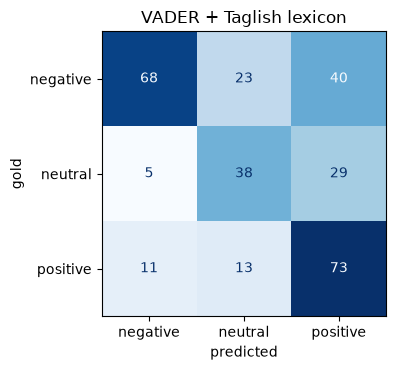

{'model': 'VADER + Taglish lexicon',
 'tier': '1 rule-based',
 'accuracy': 0.5966666666666667,
 'macro_f1': 0.5879949152760764,
 'hard_acc': 0.7,
 'sec_per_1k': 0.17435299999002987,
 'cost_per_1k_usd': 0.0}

In [6]:
def taglish_predict(texts):
    return [vader_label(tl.polarity_scores(for_vader(t))["compound"]) for t in texts]

pred_tl, sec_tl = ev.timed_predict(taglish_predict, test["text"])
hard_tl = taglish_predict(hard["text"])

zero = sum(tl.polarity_scores(t)["compound"] == 0 for t in test["text_vader"])
print(f"{zero}/{len(test)} test comments still get compound = 0")
ev.report(test["label"], pred_tl, "VADER + Taglish lexicon")
ev.plot_confusion(test["label"], pred_tl, "VADER + Taglish lexicon")
plt.show()
ev.save_run("VADER + Taglish lexicon", "1 rule-based", test, pred_tl, hard, hard_tl, sec_tl)

### Does the ±0.05 cut-off suit this data?

Checked on the **training** set only (choosing a setting by looking at the test set would be cheating).

In [7]:
comp_train = [tl.polarity_scores(t)["compound"] for t in train["text_vader"]]
rows = []
for th in [0.05, 0.1, 0.2, 0.3, 0.4, 0.5]:
    p = [vader_label(c, th, -th) for c in comp_train]
    rows.append({"threshold": th, **ev.scores(train["label"], p)})
pd.DataFrame(rows).round(3)

,threshold,accuracy,macro_f1
0,0.05,0.591,0.580
1,0.10,0.579,0.568
2,0.20,0.564,0.556
3,0.30,0.554,0.550
4,0.40,0.541,0.543
5,0.50,0.501,0.507


## 3. What does VADER + Taglish still get wrong?

In [8]:
err = test.assign(pred=pred_tl, compound=[tl.polarity_scores(t)["compound"] for t in test["text_vader"]])
err = err[err["pred"] != err["label"]]
print(len(err), "errors")
mask_frame(err[["text_clean", "label", "pred", "compound"]].sample(12, random_state=3))

121 errors


,text_clean,label,pred,compound
246,tama ang TEAm L.A dapat ang panalo halatang pi...,negative,positive,0.6331
297,sinasabihan nila palagi na bading si ABRA eto ...,neutral,positive,0.5204
15,Galing nila loonie at abra bakit sila pa na ta...,negative,neutral,0.0000
268,Ahahahaha ambakla ni Shehyee!,negative,positive,0.5093
244,NAKU GANITO LANG YAN EHHHH.....PAG TALO IDOL M...,negative,positive,0.1280
16,walang laman mga binitawan ni smugglaz at sheh...,negative,neutral,0.0000
142,kampi c target sa ss! hehe :),negative,positive,0.7424
59,loonie bawi ka namn idol pinahiya ka idol,negative,positive,0.7184
269,away naLang sana! hehe :) bugbugan na Lang mas...,neutral,positive,0.8926
48,hindi pinopost yung iba video kasi may audienc...,neutral,negative,-0.3818


In [9]:
mask_frame(pd.DataFrame({"text": hard["text"], "gold": hard["label"], "stock": hard_stock,
                         "taglish": hard_tl, "phenomenon": hard["phenomenon"]}))

,text,gold,stock,taglish,phenomenon
0,Hindi magaling si Loonie dito.,negative,neutral,negative,negation
1,Hindi naman pangit yung laban eh.,positive,neutral,positive,negation
2,Walang kwenta yung rebuttal nila.,negative,neutral,negative,negation
3,Wala akong masabi sa galing ni Smugglaz.,positive,neutral,positive,negation
4,T**g i*a ang lupet ng bara ni Abra!,positive,neutral,positive,profanity_as_praise
5,"P*******a, ang bangis talaga ng round 3!",positive,neutral,positive,profanity_as_praise
6,"G**o, pinakasolid na dos por dos 'to.",positive,neutral,negative,profanity_as_praise
7,"Wow, ang galing mag-choke ni Shehyee. Idol tal...",negative,positive,positive,sarcasm
8,"Ang husay naman ng judges, 7-0 agad. Sobrang f...",negative,positive,positive,sarcasm
9,Ganda ng laban sana kaso luto.,negative,neutral,negative,contrast


**Typical failure patterns** (write your own observations here after running):
- insults with words VADER does not know (new slang, creative spellings) → neutral
- profanity used as hype ("t\*\*\*\*\*a ang lupet") is pulled down by *t\*\*\*\*\*a*
- sarcasm ("ang galing mag-choke") is read literally as praise
- fan-war comments that cheer one team while insulting the other: the gold label is negative,
  but the praise words often win